# Topic: Using CNNs to extract properties of qubits

**Qubits.** A qubit is a two-level quantum system with states $|0\rangle$ and $|1\rangle$, separated in energy by $\hbar\omega_q$, where $\omega_q$ is the qubit frequency. Measuring it gives 0 or 1, with probabilities set by its state. We control it by driving it with a microwave pulse of frequency $\omega_d$ and strength $\Omega$, the Rabi frequency.

**Rabi oscillations.** Start in $|0\rangle$ and drive for a time $t$, with detuning $\Delta = \omega_d - \omega_q$. The probability of finding the qubit in $|1\rangle$ is
$$P_1(\Delta, t) = \frac{\Omega^2}{\Omega^2+\Delta^2}\,\sin^2\!\left(\frac{\sqrt{\Omega^2+\Delta^2}\;t}{2}\right).$$
On resonance ($\Delta=0$) the qubit swings fully between $|0\rangle$ and $|1\rangle$. Off resonance it oscillates faster, but never fully flips.

**The chevron.** Plot $P_1$ as an image, with drive frequency $\omega_d$ on one axis and pulse duration $t$ on the other. The fringes bend into nested V shapes, a *chevron*, centered on $\omega_d = \omega_q$. In a real device the fringes also fade with $t$ because of decoherence. We model this as $P_1 = \frac{\Omega^2}{\Omega^2+\Delta^2}\cdot\tfrac12\big[1-e^{-t/T_2}\cos(\sqrt{\Omega^2+\Delta^2}\,t)\big]$.

**What it tells us.**
- $\omega_q$, the qubit frequency: where the chevron's symmetry axis sits.
- $\Omega$, the drive strength: the fringe period on resonance, $2\pi/\Omega$. This sets the $\pi$-pulse time $\pi/\Omega$ used for a NOT gate.
- $T_2$, the coherence time: how quickly the fringe contrast decays along $t$.

**Synthetic data and noise.** We sample random $(\omega_q, \Omega, T_2)$, render the chevron on a fixed $(\omega_d, t)$ grid, and add noise. The noise has two parts: shot noise (each pixel is an average of $N$ binary measurements) and Gaussian readout noise. Because we generate every image ourselves, we know its true parameters exactly. That makes this a supervised regression problem: image $\to (\omega_q, \Omega, T_2)$.

**Why a CNN.** Each parameter shows up as a local spatial feature that can sit anywhere in the image. $\omega_q$ moves the whole pattern sideways, $\Omega$ sets the fringe spacing, and $T_2$ sets how quickly contrast fades. Convolutions share their weights across the image, so a filter that detects a fringe or the V's apex works wherever that feature appears. That uses far fewer parameters than a dense network. Pooling and stacked layers average over pixel-level noise while keeping the overall shape. Unlike fitting a curve to each image, a trained CNN needs no starting guess and gives its answer in one forward pass.

*Conventions:* $\hbar = 1$; all frequencies are angular and in the same units, with $t$ in the inverse of those units.

In [11]:
# Import relevant libraries
import numpy as np
import torch 
import matplotlib.pyplot as plt

## Generating the chevron patterns

We don't draw the chevron by hand. We pick the qubit's physical properties and compute what the experiment would measure.

**Inputs (the labels we choose):**
- $\omega_q$, the qubit frequency, which sets where the pattern is centered;
- $\Omega$, the Rabi frequency (drive strength), which sets the fringe spacing;
- $T_2$, the coherence time, which sets how fast the fringes fade.

**Physics.** In the frame rotating with the drive, $H = \tfrac{\Delta}{2}\sigma_z + \tfrac{\Omega}{2}\sigma_x$ with $\Delta = \omega_d - \omega_q$. Starting in $|0\rangle$, the qubit precesses at the generalized Rabi frequency $\Omega_R = \sqrt{\Omega^2+\Delta^2}$. Including dephasing, the probability of measuring $|1\rangle$ is
$$P_1(\omega_d, t) = \frac{\Omega^2}{\Omega_R^2}\cdot\frac12\Big[1 - e^{-t/T_2}\cos(\Omega_R t)\Big].$$
- The prefactor $\Omega^2/\Omega_R^2$ is a Lorentzian in $\Delta$, so the fringes are brightest at $\omega_d = \omega_q$.
- $\Omega_R$ grows with $|\Delta|$, so the oscillations speed up away from resonance. Lines of constant phase curve inward toward $\omega_q$, forming the V shapes.
- The factor $e^{-t/T_2}$ washes the fringes out at long $t$, and $P_1$ settles to $\tfrac12\,\Omega^2/\Omega_R^2$.

**From physics to image.**
1. Fix the measurement grid: 64 drive frequencies $\omega_d \in [-6, 6]$ and 64 pulse durations $t \in [0, 10]$.
2. Evaluate $P_1$ at every $(\omega_d, t)$ pair, using array broadcasting. The result is a $64\times64$ noiseless image.
3. Add realistic noise:
   - shot noise, with each pixel equal to $\text{Binomial}(N, P_1)/N$ for $N = 100$ shots;
   - Gaussian readout noise with $\sigma = 0.03$.
4. For the dataset, draw $\omega_q \in [-2, 2]$, $\Omega \in [1, 3]$, and $T_2 \in [2, 20]$ (log-uniform, since it spans a factor of 10) at random for each image. These ranges keep 1.6–4.8 Rabi periods and a visible decay inside the $t \in [0, 10]$ window. Store each image together with its parameters $(\omega_q, \Omega, T_2)$, which are its exact labels.

**Check.** Compare the formula against direct time evolution, $|\langle 1|e^{-iHt}|0\rangle|^2$ computed with a matrix exponential, at a few $(\Delta, t)$ points with $T_2 \to \infty$. On resonance, a pulse of length $t = \pi/\Omega$ must give $P_1 = 1$.

In [12]:
# Generation of the chevron patterns with no noise
# Units: hbar = 1, all frequencies angular, times in inverse frequency units.

drive_freqs = np.linspace(-6, 6, 64)   # omega_d: horizontal axis of the image
pulse_times = np.linspace(0, 10, 64)   # t: vertical axis of the image

def probability_excitedstate(drive_freq, pulse_time, qubit_freq, rabi_freq, coherence_time):
    """Probability of measuring |1> after driving |0> for pulse_time at drive_freq."""
    detuning = drive_freq - qubit_freq
    rabi_oscillation_freq = np.sqrt(rabi_freq**2 + detuning**2)   # Omega_R: actual oscillation rate
    amplitude = rabi_freq**2 / rabi_oscillation_freq**2           # Lorentzian: 1 on resonance
    decay = np.exp(-pulse_time / coherence_time)                  # dephasing washes out fringes
    return amplitude * 0.5 * (1 - decay * np.cos(rabi_oscillation_freq * pulse_time))

def generate_chevron_pattern(qubit_freq, rabi_freq, coherence_time):
    """64x64 image of P_1: rows are pulse times, columns are drive frequencies."""
    return probability_excitedstate(drive_freqs[None, :], pulse_times[:, None],
                                    qubit_freq, rabi_freq, coherence_time)

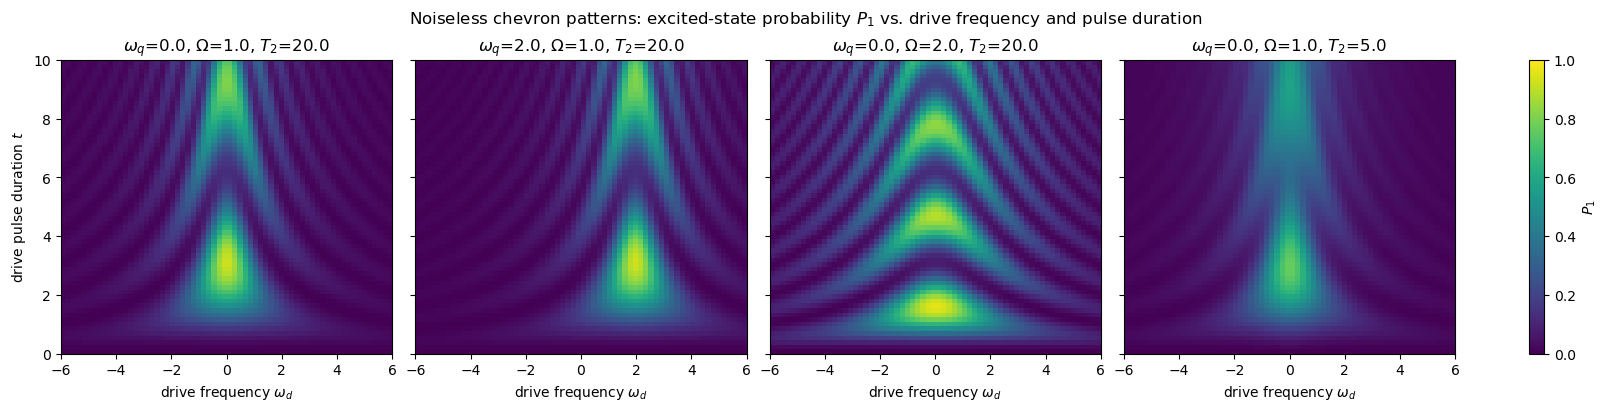

In [13]:
# Plot some sample chevron patterns: a reference, then change one parameter at a time
sample_params = [  # (qubit_freq, rabi_freq, coherence_time)
    (0.0, 1.0, 20.0),   # reference
    (2.0, 1.0, 20.0),   # shifted qubit frequency -> pattern moves sideways
    (0.0, 2.0, 20.0),   # stronger drive -> faster, wider fringes
    (0.0, 1.0, 5.0),    # short coherence time -> fringes fade quickly
]
image_extent = [drive_freqs[0], drive_freqs[-1], pulse_times[0], pulse_times[-1]]

fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True, constrained_layout=True)
for ax, (qubit_freq, rabi_freq, coherence_time) in zip(axes, sample_params):
    pattern = generate_chevron_pattern(qubit_freq, rabi_freq, coherence_time)
    image = ax.imshow(pattern, origin='lower', aspect='auto', extent=image_extent, vmin=0, vmax=1)
    ax.set_title(rf'$\omega_q$={qubit_freq}, $\Omega$={rabi_freq}, $T_2$={coherence_time}')
    ax.set_xlabel(r'drive frequency $\omega_d$')
axes[0].set_ylabel('drive pulse duration $t$')
fig.colorbar(image, ax=axes, label='$P_1$')
fig.suptitle('Noiseless chevron patterns: excited-state probability $P_1$ vs. drive frequency and pulse duration')
plt.show()

In [15]:
# Generate the chevron patterns with noise
rng = np.random.default_rng(seed=0)   # fixed seed so the dataset is reproducible

def noise_model(pattern, num_shots=100, readout_noise_std=0.03):
    """Turn a noiseless P_1 image into a realistic measured image."""
    # Shot noise: each pixel is the fraction of num_shots single measurements that returned |1>
    measured_fraction = rng.binomial(num_shots, pattern) / num_shots
    # Readout noise: detector electronics add Gaussian jitter to every pixel
    readout_noise = rng.normal(0, readout_noise_std, pattern.shape)
    return measured_fraction + readout_noise

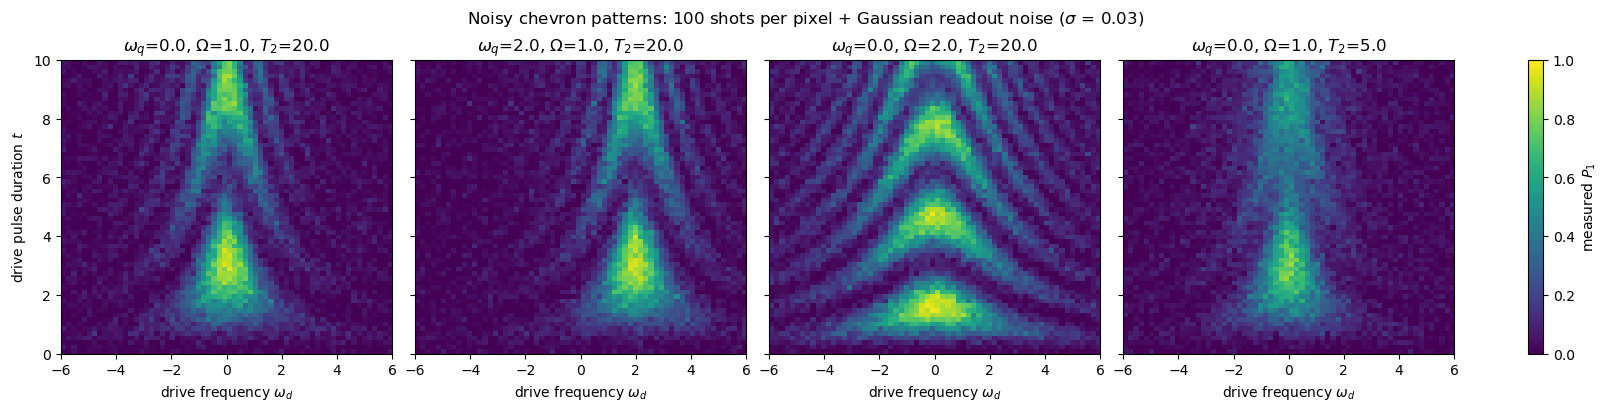

In [16]:
# Plot some sample chevron patterns with noise: a reference, then change one parameter at a time
sample_params = [  # (qubit_freq, rabi_freq, coherence_time)
    (0.0, 1.0, 20.0),   # reference
    (2.0, 1.0, 20.0),   # shifted qubit frequency -> pattern moves sideways
    (0.0, 2.0, 20.0),   # stronger drive -> faster, wider fringes
    (0.0, 1.0, 5.0),    # short coherence time -> fringes fade quickly
]

fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True, constrained_layout=True)
for ax, (qubit_freq, rabi_freq, coherence_time) in zip(axes, sample_params):
    noisy_pattern = noise_model(generate_chevron_pattern(qubit_freq, rabi_freq, coherence_time))
    image = ax.imshow(noisy_pattern, origin='lower', aspect='auto', extent=image_extent, vmin=0, vmax=1)
    ax.set_title(rf'$\omega_q$={qubit_freq}, $\Omega$={rabi_freq}, $T_2$={coherence_time}')
    ax.set_xlabel(r'drive frequency $\omega_d$')
axes[0].set_ylabel('drive pulse duration $t$')
fig.colorbar(image, ax=axes, label='measured $P_1$')
fig.suptitle('Noisy chevron patterns: 100 shots per pixel + Gaussian readout noise ($\\sigma$ = 0.03)')
plt.show()

In [17]:
# Dataset generation: 20000 chevron patterns with random parameters, plus noise
num_samples = 20000
qubit_freqs = rng.uniform(-2, 2, num_samples)                               # uniform
rabi_freqs = rng.uniform(1, 3, num_samples)                                 # uniform
coherence_times = np.exp(rng.uniform(np.log(2), np.log(20), num_samples))   # log-uniform

noisy_images = np.stack([noise_model(generate_chevron_pattern(qubit_freq, rabi_freq, coherence_time))
                         for qubit_freq, rabi_freq, coherence_time
                         in zip(qubit_freqs, rabi_freqs, coherence_times)])
labels = np.stack([qubit_freqs, rabi_freqs, coherence_times], axis=1)   # columns: (omega_q, Omega, T2)

print('images:', noisy_images.shape, ' labels:', labels.shape)

images: (20000, 64, 64)  labels: (20000, 3)


## Using a CNN to read the noisy images

**Data.** 20,000 noisy $64\times64$ images, each paired with its true $(\omega_q, \Omega, T_2)$. Split 80/10/10:
- **train** (16,000): fit the weights;
- **validation** (2,000): watch for overfitting while training;
- **test** (2,000): measure final accuracy, used only once.

**Labels.** Rescale each label to $[0, 1]$ so the three are weighted equally in the loss. $T_2$ is rescaled on a log scale, since it spans a factor of 10. Network outputs are converted back to physical units before we compare them with the truth.

**Network.** Each image enters as one channel.
- Convolution layers slide small $3\times3$ filters over the image to pick up local features: fringe edges, their spacing, and the apex of the V.
- ReLU makes the response nonlinear. Max-pooling halves the resolution, so later filters see larger regions while pixel noise is averaged out ($64 \to 32 \to 16$).
- Fully connected layers combine these features into three numbers: $(\hat\omega_q, \hat\Omega, \hat T_2)$.

**Training.** Minimize the mean squared error between predicted and true labels, using the Adam optimizer on mini-batches of training images. Track the validation loss each epoch; it should fall along with the training loss.

**Evaluation.** On the test set, plot predicted against true for each parameter, and report $R^2$ and the relative error. We expect $\omega_q$ to be the easiest, since it's a sideways shift of the whole pattern, and $T_2$ the hardest, since a long $T_2$ barely changes the image within $t \le 10$.


In [18]:
# CNN: label scaling, train/val/test split, and the network

# Label scaling: map each label to [0, 1] so all three weigh equally in the loss.
# T2 is scaled on a log axis because it spans a factor of 10.
label_min = np.array([-2.0, 1.0, np.log(2.0)])    # (omega_q, Omega, log T2) at the bottom of each range
label_max = np.array([ 2.0, 3.0, np.log(20.0)])   # ... and at the top

def scale_labels(physical_labels):
    """Physical (omega_q, Omega, T2) -> values in [0, 1]."""
    log_labels = np.column_stack([physical_labels[:, 0], physical_labels[:, 1], np.log(physical_labels[:, 2])])
    return (log_labels - label_min) / (label_max - label_min)

def unscale_labels(scaled_labels):
    """Values in [0, 1] -> physical (omega_q, Omega, T2)."""
    log_labels = label_min + scaled_labels * (label_max - label_min)
    return np.column_stack([log_labels[:, 0], log_labels[:, 1], np.exp(log_labels[:, 2])])

# Tensors: images get a channel axis -> (N, 1, 64, 64)
images_tensor = torch.tensor(noisy_images, dtype=torch.float32).unsqueeze(1)
labels_tensor = torch.tensor(scale_labels(labels), dtype=torch.float32)

# 80/10/10 split (parameters were drawn independently, so the dataset is already in random order)
split_sizes = [int(0.8 * num_samples), int(0.1 * num_samples), int(0.1 * num_samples)]
train_images, val_images, test_images = torch.split(images_tensor, split_sizes)
train_labels, val_labels, test_labels = torch.split(labels_tensor, split_sizes)

def build_cnn(input_shape):
    """Two conv + pool blocks (64 -> 32 -> 16 pixels), then a dense head with 3 outputs."""
    model = torch.nn.Sequential(
        torch.nn.Conv2d(1, 16, kernel_size=3, padding=1),  # input channels, output channels, kernel size
        torch.nn.ReLU(),
        torch.nn.MaxPool2d(2),  # downsample by factor of 2
        torch.nn.Conv2d(16, 32, kernel_size=3, padding=1),
        torch.nn.ReLU(),
        torch.nn.MaxPool2d(2),
        torch.nn.Flatten(),
        torch.nn.Linear(32 * (input_shape[0] // 4) * (input_shape[1] // 4), 128),  # adjust for pooling
        torch.nn.ReLU(),
        torch.nn.Linear(128, 3)  # output: scaled (omega_q, Omega, T2)
    )
    return model

model = build_cnn(noisy_images.shape[1:])

# Checks: scaling round-trips exactly, labels land in [0, 1], and the network maps images to 3 numbers
assert np.allclose(unscale_labels(scale_labels(labels)), labels)
assert labels_tensor.min() >= 0 and labels_tensor.max() <= 1
assert model(train_images[:8]).shape == (8, 3)
print('train/val/test:', len(train_images), len(val_images), len(test_images))
print('trainable parameters:', sum(p.numel() for p in model.parameters()))


train/val/test: 16000 2000 2000
trainable parameters: 1053891


Tiny-batch check: loss 0.3471 -> 0.000017
Epoch 1/20, Train Loss: 1.04e-02, Val Loss: 7.29e-04
Epoch 2/20, Train Loss: 4.21e-04, Val Loss: 3.87e-04
Epoch 3/20, Train Loss: 2.63e-04, Val Loss: 2.13e-04
Epoch 4/20, Train Loss: 2.71e-04, Val Loss: 2.56e-04
Epoch 5/20, Train Loss: 2.71e-04, Val Loss: 2.90e-04
Epoch 6/20, Train Loss: 2.09e-04, Val Loss: 1.66e-04
Epoch 7/20, Train Loss: 1.98e-04, Val Loss: 1.50e-04
Epoch 8/20, Train Loss: 2.68e-04, Val Loss: 1.68e-04
Epoch 9/20, Train Loss: 2.29e-04, Val Loss: 1.59e-04
Epoch 10/20, Train Loss: 1.58e-04, Val Loss: 1.29e-04
Epoch 11/20, Train Loss: 1.63e-04, Val Loss: 3.52e-04
Epoch 12/20, Train Loss: 1.80e-04, Val Loss: 1.95e-04
Epoch 13/20, Train Loss: 1.75e-04, Val Loss: 1.77e-04
Epoch 14/20, Train Loss: 1.86e-04, Val Loss: 1.28e-04
Epoch 15/20, Train Loss: 1.50e-04, Val Loss: 1.10e-04
Epoch 16/20, Train Loss: 1.38e-04, Val Loss: 1.15e-04
Epoch 17/20, Train Loss: 1.29e-04, Val Loss: 1.14e-04
Epoch 18/20, Train Loss: 1.42e-04, Val Loss: 1.11

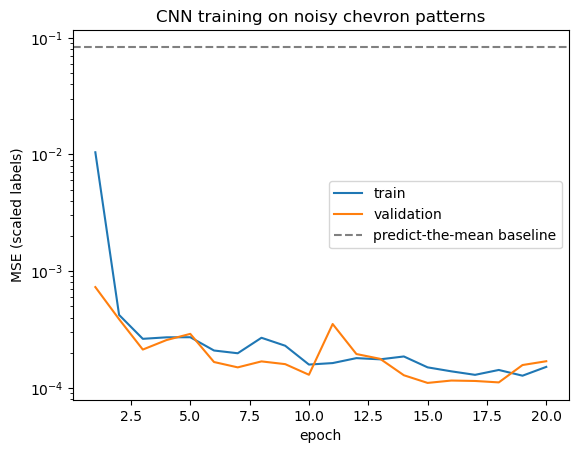

In [19]:
# Training the CNN
# Loss function: mean squared error (MSE) between predicted and true scaled labels
loss_fn = torch.nn.MSELoss()

def train_model(model, train_images, train_labels, val_images, val_labels, num_epochs=20, batch_size=64, learning_rate=1e-3, verbose=True):
    """Train the CNN model and return the training and validation losses."""
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    train_losses = []
    val_losses = []

    for epoch in range(num_epochs):
        # Training phase
        model.train()
        permutation = torch.randperm(train_images.size(0))
        epoch_train_loss = 0.0

        for i in range(0, train_images.size(0), batch_size):
            indices = permutation[i:i + batch_size]
            batch_images, batch_labels = train_images[indices], train_labels[indices]

            optimizer.zero_grad()
            outputs = model(batch_images)
            loss = loss_fn(outputs, batch_labels)
            loss.backward()
            optimizer.step()

            epoch_train_loss += loss.item() * batch_images.size(0)

        epoch_train_loss /= len(train_images)
        train_losses.append(epoch_train_loss)

        # Validation phase
        model.eval()
        with torch.no_grad():
            val_outputs = model(val_images)
            val_loss = loss_fn(val_outputs, val_labels).item()
            val_losses.append(val_loss)

        if verbose:
            print(f'Epoch {epoch + 1}/{num_epochs}, Train Loss: {epoch_train_loss:.2e}, Val Loss: {val_loss:.2e}')

    return train_losses, val_losses


torch.manual_seed(0)   # reproducible weight initialization and batch order

# Check 1: a fresh network must be able to memorize 32 images (loss -> ~0).
# If it can't, the model or the label wiring is broken, and training on the full set is pointless.
tiny_model = build_cnn(noisy_images.shape[1:])
tiny_train_losses, _ = train_model(tiny_model, train_images[:32], train_labels[:32], val_images, val_labels,
                                   num_epochs=200, batch_size=32, verbose=False)
print(f'Tiny-batch check: loss {tiny_train_losses[0]:.4f} -> {tiny_train_losses[-1]:.6f}')

# Full training
train_losses, val_losses = train_model(model, train_images, train_labels, val_images, val_labels)

# Check 2: loss curves. Reference: always predicting the mean scaled label gives
# MSE = variance of a uniform [0, 1] variable = 1/12, so the CNN must end far below that line.
mean_guess_mse = 1 / 12
epochs = np.arange(1, len(train_losses) + 1)
plt.semilogy(epochs, train_losses, label='train')
plt.semilogy(epochs, val_losses, label='validation')
plt.axhline(mean_guess_mse, color='gray', linestyle='--', label='predict-the-mean baseline')
plt.xlabel('epoch')
plt.ylabel('MSE (scaled labels)')
plt.title('CNN training on noisy chevron patterns')
plt.legend()
plt.show()


Test Loss: 1.74e-04


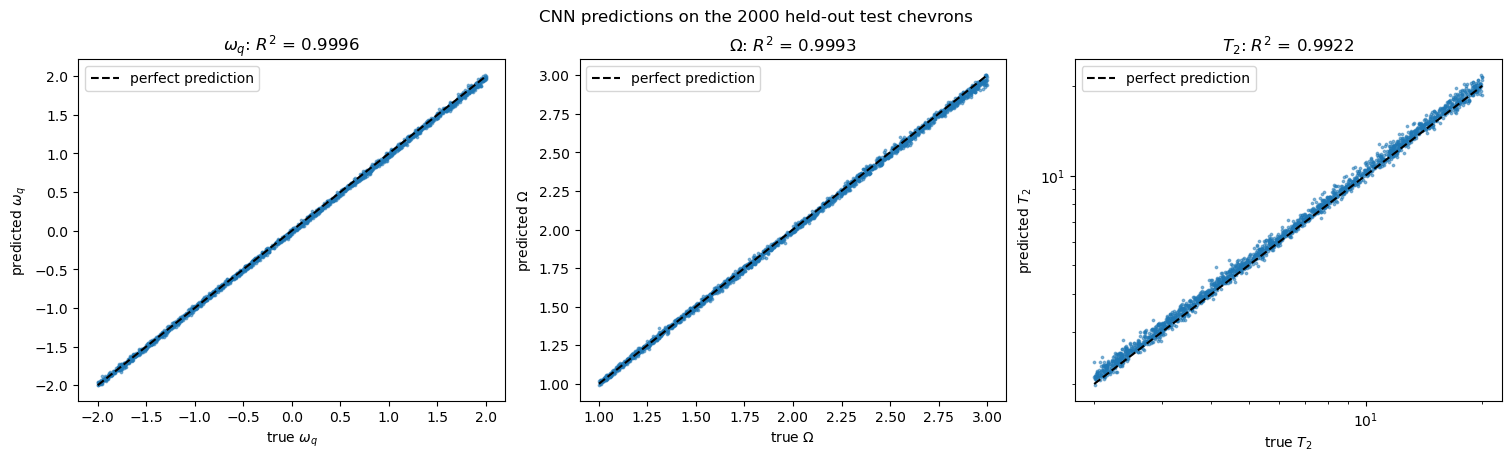

median |error| in omega_q : 0.0164  (pixel spacing: 0.190)
median relative error in Omega: 0.50%
median relative error in T2   : 3.32%
T2 relative error, short T2: 3.55%,  long T2: 3.09%


In [20]:
# Evaluation on the test set
model.eval()
with torch.no_grad():
    test_outputs = model(test_images)
    test_loss = loss_fn(test_outputs, test_labels).item()
    print(f'Test Loss: {test_loss:.2e}')    

# Convert scaled outputs back to physical units: columns (omega_q, Omega, T2)
predicted_params = unscale_labels(test_outputs.numpy())
true_params = unscale_labels(test_labels.numpy())

# Predicted vs. true for each parameter; points on the dashed line are perfect predictions
param_names = [r'$\omega_q$', r'$\Omega$', r'$T_2$']
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)
for k, (ax, name) in enumerate(zip(axes, param_names)):
    true, predicted = true_params[:, k], predicted_params[:, k]
    r_squared = 1 - np.sum((predicted - true)**2) / np.sum((true - true.mean())**2)
    ax.scatter(true, predicted, s=3, alpha=0.5)
    ax.plot([true.min(), true.max()], [true.min(), true.max()], 'k--', label='perfect prediction')
    ax.set(title=f'{name}: $R^2$ = {r_squared:.4f}', xlabel=f'true {name}', ylabel=f'predicted {name}')
    ax.legend()
axes[2].set(xscale='log', yscale='log')   # T2 was sampled log-uniformly
fig.suptitle('CNN predictions on the 2000 held-out test chevrons')
plt.show()

# Typical errors: absolute for omega_q (it can be ~0), relative for Omega and T2
qubit_freq_error = np.abs(predicted_params[:, 0] - true_params[:, 0])
rabi_freq_rel_error = np.abs(predicted_params[:, 1] / true_params[:, 1] - 1)
coherence_time_rel_error = np.abs(predicted_params[:, 2] / true_params[:, 2] - 1)
print(f'median |error| in omega_q : {np.median(qubit_freq_error):.4f}  (pixel spacing: {drive_freqs[1] - drive_freqs[0]:.3f})')
print(f'median relative error in Omega: {np.median(rabi_freq_rel_error):.2%}')
print(f'median relative error in T2   : {np.median(coherence_time_rel_error):.2%}')

# Physics check: how does T2 accuracy depend on T2? Long T2 shows little decay within t <= 10;
# short T2 kills the fringes after ~1 oscillation, leaving little signal above the noise.
long_coherence = true_params[:, 2] > np.median(true_params[:, 2])
print(f'T2 relative error, short T2: {np.median(coherence_time_rel_error[~long_coherence]):.2%},'
      f'  long T2: {np.median(coherence_time_rel_error[long_coherence]):.2%}')
